# DataXperience KINNUX
## Análisis de ventas y comportamiento comercial mediante Ciencia de Datos

**Proyecto:** DataXperience  
**Empresa analizada:** KINNUX S.A.S.  
**Área:** Ciencia de Datos / Ingeniería de Sistemas

### Descripción

Este proyecto tiene como objetivo analizar información comercial de KINNUX mediante técnicas de preparación, transformación, exploración y análisis de datos.

El conjunto de datos utilizado parte de registros comerciales reales que fueron anonimizados para proteger la información de clientes y colaboradores.

Adicionalmente, se dispone de una base ampliada con datos sintéticos generados a partir de los patrones observados en los registros originales, exclusivamente con fines académicos.

En esta primera etapa se realizará la exploración y preparación del conjunto de datos, identificando valores faltantes, inconsistencias, tipos de variables y posibles problemas de calidad.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [2]:
archivo = "https://github.com/JuanGo2412/proyecto-dataXperience/blob/main/datos/Data%20Frame.xlsx?raw=true"

df = pd.read_excel(
    archivo,
    sheet_name="00_Base_Anonimizada"
)

df["Producto"] = df["Producto"].str.replace(r"\\\*", "*", regex=True).str.strip()

print("Dataset cargado correctamente.")

Dataset cargado correctamente.


In [3]:
df.head()

,ID_Registro,ID_Pedido,Fecha,Asesor_ID,Producto,Cantidad,Tipo,Valor_Total_COP,Medio_Pago,Estado_Pago,Cliente_ID,Canal_Entrega,Origen_Dato
0,R0001,PED_R0001,2026-07-01,ASE_01,NAD,1.0,VENTA,115000.0,EFECTIVO,PAGADO,CLI_001,OFICINA,REAL_ANONIMIZADO
1,R0002,PED_R0001,2026-07-01,ASE_01,FIBRA,1.0,VENTA,110000.0,EFECTIVO,PAGADO,CLI_001,NO_ESPECIFICADO,REAL_ANONIMIZADO
2,R0003,PED_R0002,2026-07-01,ASE_02,COLON,1.0,VENTA,165000.0,NEQUI,PAGADO,CLI_002,OFICINA,REAL_ANONIMIZADO
3,R0004,PED_R0002,2026-07-01,ASE_02,D-TOX,1.0,OBSEQUIO,0.0,NO_REGISTRADO,OBSEQUIO,CLI_002,NO_ESPECIFICADO,REAL_ANONIMIZADO
4,R0005,PED_R0003,2026-07-01,ASE_01,NGYPLUS,50.0,VENTA,3500000.0,TRANSFERENCIA,PAGADO,CLI_003,DOMICILIO,REAL_ANONIMIZADO


In [4]:
df.shape

(181, 13)

### Dimensiones del conjunto de datos

El conjunto de datos contiene 181 registros y 13 variables.  
Cada fila representa un registro comercial y las columnas contienen información relacionada con la fecha, producto, cantidad, valor de la venta, medio de pago, estado, cliente y canal de entrega.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 181 entries, 0 to 180
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   ID_Registro      181 non-null    object        
 1   ID_Pedido        181 non-null    object        
 2   Fecha            181 non-null    datetime64[ns]
 3   Asesor_ID        181 non-null    object        
 4   Producto         179 non-null    object        
 5   Cantidad         179 non-null    float64       
 6   Tipo             170 non-null    object        
 7   Valor_Total_COP  131 non-null    float64       
 8   Medio_Pago       181 non-null    object        
 9   Estado_Pago      181 non-null    object        
 10  Cliente_ID       179 non-null    object        
 11  Canal_Entrega    181 non-null    object        
 12  Origen_Dato      181 non-null    object        
dtypes: datetime64[ns](1), float64(2), object(10)
memory usage: 18.5+ KB


### Tipos de variables

Se utilizó `df.info()` para revisar la estructura del conjunto de datos, identificar el tipo de cada variable y observar si existen valores faltantes.

Esta revisión permite detectar columnas numéricas, columnas de texto y posibles datos incompletos que deberán ser analizados durante la etapa de limpieza.

### Interpretación de la estructura del dataset

El conjunto de datos contiene 181 registros y 13 variables.

La mayoría de las variables son de tipo texto, mientras que las columnas `Cantidad` y `Valor_Total_COP` son numéricas y la columna `Fecha` corresponde a un dato de tipo fecha.

También se identificaron algunos valores faltantes en variables como `Producto`, `Cantidad`, `Tipo`, `Valor_Total_COP` y `Cliente_ID`.

Estos valores serán revisados en la etapa de limpieza de datos.

In [6]:
df.isnull().sum()

,0
ID_Registro,0
ID_Pedido,0
Fecha,0
Asesor_ID,0
Producto,2
Cantidad,2
Tipo,11
Valor_Total_COP,50
Medio_Pago,0
Estado_Pago,0


### Valores faltantes

Se utilizó `df.isnull().sum()` para identificar la cantidad de datos faltantes en cada variable.

Los principales resultados fueron:

- `Producto`: 2 valores faltantes.
- `Cantidad`: 2 valores faltantes.
- `Tipo`: 11 valores faltantes.
- `Valor_Total_COP`: 50 valores faltantes.
- `Cliente_ID`: 2 valores faltantes.

La variable con mayor cantidad de datos faltantes es `Valor_Total_COP`.

Estos registros serán revisados antes de realizar los análisis para evitar resultados incorrectos.

In [7]:
df.duplicated().sum()

np.int64(0)

### Registros duplicados

Se utilizó `df.duplicated().sum()` para verificar si existían filas completamente repetidas dentro del conjunto de datos.

El resultado fue 0, por lo tanto no se encontraron registros duplicados.

In [8]:
df.describe()

,Fecha,Cantidad,Valor_Total_COP
count,181,179.000000,1.310000e+02
mean,2026-09-15 16:58:20.552486144,9.391061,3.935000e+05
min,2026-07-01 00:00:00,1.000000,0.000000e+00
25%,2026-09-08 00:00:00,1.000000,9.600000e+04
50%,2026-09-23 00:00:00,2.000000,1.800000e+05
75%,2026-10-07 00:00:00,4.000000,3.480000e+05
max,2026-10-26 00:00:00,300.000000,4.000000e+06
std,NaN,30.415718,6.953731e+05


### Resumen estadístico

Se utilizó `df.describe()` para conocer el comportamiento general de las variables numéricas.

Se encontró que la cantidad promedio registrada es de aproximadamente 9 unidades, aunque el 50 % de los registros tiene 2 unidades o menos. También se observan operaciones de mayor volumen, llegando hasta 300 unidades.

En la variable `Valor_Total_COP`, el valor promedio es aproximadamente $393.500 y la mediana es $180.000. El valor máximo registrado es $4.000.000.

También existen registros con valor igual a $0, los cuales deben revisarse antes de considerarlos errores, ya que pueden corresponder a obsequios u operaciones pendientes.

In [9]:
df["Tipo"].value_counts(dropna=False)

,count
Tipo,
VENTA,156
OBSEQUIO,14
NaN,11


### Tipos de registro

Se revisó la variable `Tipo` para identificar la naturaleza de cada movimiento.

Se encontraron:

- 156 registros correspondientes a ventas.
- 14 registros correspondientes a obsequios.
- 11 registros sin información en esta variable.

Los registros sin información deberán revisarse durante la etapa de limpieza para determinar cómo deben ser tratados.

In [10]:
df["Estado_Pago"].value_counts()

,count
Estado_Pago,
PAGADO,95
PENDIENTE,49
NO_REGISTRADO,23
OBSEQUIO,14


### Estado de pago

Se revisó la variable `Estado_Pago` para conocer la situación de los registros comerciales.

Se encontraron:

- 95 registros pagados.
- 49 registros pendientes de pago.
- 23 registros sin estado de pago registrado.
- 14 registros correspondientes a obsequios.

Esta información será importante para diferenciar posteriormente las ventas efectivamente pagadas de los registros pendientes, no registrados y obsequios.

In [11]:
df[df["Producto"].isnull() | df["Cantidad"].isnull()]

,ID_Registro,ID_Pedido,Fecha,Asesor_ID,Producto,Cantidad,Tipo,Valor_Total_COP,Medio_Pago,Estado_Pago,Cliente_ID,Canal_Entrega,Origen_Dato
42,R0043,PED_R0024,2026-09-04,ASE_03,NaN,NaN,VENTA,120000.0,EFECTIVO,PAGADO,CLI_021,NO_ESPECIFICADO,REAL_ANONIMIZADO
56,R0057,PED_R0036,2026-09-11,ASE_03,NaN,NaN,VENTA,318000.0,NEQUI,PAGADO,CLI_029,NO_ESPECIFICADO,REAL_ANONIMIZADO


In [12]:
df["Producto"] = df["Producto"].fillna("NO_REGISTRADO")

In [13]:
df["Producto"].isnull().sum()

np.int64(0)

### Tratamiento de productos faltantes

Se encontraron 2 registros de ventas pagadas en los que no estaba identificado el producto ni la cantidad vendida.

Debido a que estos registros sí contienen un valor de venta válido, se decidió conservarlos para no perder información económica.

Los valores faltantes de la variable `Producto` fueron reemplazados por la categoría `NO_REGISTRADO`.

La cantidad se mantuvo como dato faltante, ya que no existe información suficiente para determinar su valor y no se consideró correcto inventarlo.

In [14]:
df[df["Tipo"].isnull()]

,ID_Registro,ID_Pedido,Fecha,Asesor_ID,Producto,Cantidad,Tipo,Valor_Total_COP,Medio_Pago,Estado_Pago,Cliente_ID,Canal_Entrega,Origen_Dato
148,R0149,PED_R0099,2026-10-14,ASE_02,COLON,56.0,NaN,NaN,NO_REGISTRADO,NO_REGISTRADO,CLI_054,NO_ESPECIFICADO,REAL_ANONIMIZADO
149,R0150,PED_R0099,2026-10-14,ASE_02,ODIN 60ML,56.0,NaN,NaN,NO_REGISTRADO,NO_REGISTRADO,CLI_054,NO_ESPECIFICADO,REAL_ANONIMIZADO
150,R0151,PED_R0099,2026-10-14,ASE_02,NAD,32.0,NaN,NaN,NO_REGISTRADO,NO_REGISTRADO,CLI_054,NO_ESPECIFICADO,REAL_ANONIMIZADO
151,R0152,PED_R0099,2026-10-14,ASE_02,SMARTMIX,24.0,NaN,NaN,NO_REGISTRADO,NO_REGISTRADO,CLI_054,NO_ESPECIFICADO,REAL_ANONIMIZADO
152,R0153,PED_R0099,2026-10-14,ASE_02,CAFE,2.0,NaN,NaN,NO_REGISTRADO,NO_REGISTRADO,CLI_054,NO_ESPECIFICADO,REAL_ANONIMIZADO
153,R0154,PED_R0099,2026-10-14,ASE_02,KIMAAX SHOT*30 SACH,6.0,NaN,NaN,NO_REGISTRADO,NO_REGISTRADO,CLI_054,NO_ESPECIFICADO,REAL_ANONIMIZADO
154,R0155,PED_R0099,2026-10-14,ASE_02,SHAMPOO,3.0,NaN,NaN,NO_REGISTRADO,NO_REGISTRADO,CLI_054,NO_ESPECIFICADO,REAL_ANONIMIZADO
155,R0156,PED_R0099,2026-10-14,ASE_02,CONDITIONER,3.0,NaN,NaN,NO_REGISTRADO,NO_REGISTRADO,CLI_054,NO_ESPECIFICADO,REAL_ANONIMIZADO
156,R0157,PED_R0099,2026-10-14,ASE_02,LAVANDA,2.0,NaN,NaN,NO_REGISTRADO,NO_REGISTRADO,CLI_054,NO_ESPECIFICADO,REAL_ANONIMIZADO
157,R0158,PED_R0099,2026-10-14,ASE_02,MANGO,2.0,NaN,NaN,NO_REGISTRADO,NO_REGISTRADO,CLI_054,NO_ESPECIFICADO,REAL_ANONIMIZADO


In [15]:
df["Tipo"] = df["Tipo"].fillna("NO_REGISTRADO")

In [16]:
df["Tipo"].value_counts()

,count
Tipo,
VENTA,156
OBSEQUIO,14
NO_REGISTRADO,11


### Tratamiento de valores faltantes en la variable Tipo

Se encontraron 11 registros sin información en la variable `Tipo`.

Estos registros contienen producto y cantidad, pero no cuentan con información suficiente para determinar si corresponden a una venta, obsequio u otro tipo de movimiento.

Por esta razón, se decidió conservarlos y reemplazar los valores faltantes por la categoría `NO_REGISTRADO`, evitando asumir información que no está disponible en los datos originales.

In [17]:
df[df["Valor_Total_COP"].isnull()][
    ["Producto", "Cantidad", "Tipo", "Estado_Pago", "Valor_Total_COP"]
].head(15)

,Producto,Cantidad,Tipo,Estado_Pago,Valor_Total_COP
5,KIMAAX SHOT*60ML,12.0,VENTA,NO_REGISTRADO,NaN
6,KIMAAX SHOT*30 SACH,30.0,VENTA,NO_REGISTRADO,NaN
13,KIMAAX SHOT*60ML,12.0,VENTA,NO_REGISTRADO,NaN
14,KIMAAX SHOT*30 SACH,3.0,VENTA,NO_REGISTRADO,NaN
15,NAD,2.0,VENTA,PAGADO,NaN
16,KINITROX 30ML,1.0,VENTA,PAGADO,NaN
17,STEM,1.0,VENTA,PAGADO,NaN
22,SMARTMIX,1.0,VENTA,NO_REGISTRADO,NaN
23,STEM,1.0,VENTA,NO_REGISTRADO,NaN
85,KI-SHAKE CHOCOLATE,3.0,VENTA,NO_REGISTRADO,NaN


In [18]:
df[df["Valor_Total_COP"].isnull()]["Estado_Pago"].value_counts()

,count
Estado_Pago,
NO_REGISTRADO,23
PENDIENTE,20
OBSEQUIO,4
PAGADO,3


In [19]:
df.loc[
    ((df["Tipo"] == "OBSEQUIO") | (df["Estado_Pago"] == "OBSEQUIO")) & (df["Valor_Total_COP"].isnull()),
    "Valor_Total_COP"
] = 0

In [20]:
df["Valor_Total_COP"].isnull().sum()

np.int64(46)

### Tratamiento de valores faltantes en Valor_Total_COP

Se encontraron 50 registros sin información en la variable `Valor_Total_COP`.

Al revisar estos registros se identificaron 23 movimientos con estado `NO_REGISTRADO`, 20 pendientes, 4 obsequios y 3 pagos realizados.

Se decidió asignar un valor de $0 únicamente a los obsequios, ya que estos movimientos no representan ingresos por ventas.

Los demás valores se conservaron como datos faltantes porque no existe información suficiente para determinar el monto correspondiente y no se consideró adecuado inventar valores.

In [21]:
df[df["Cliente_ID"].isnull()]

,ID_Registro,ID_Pedido,Fecha,Asesor_ID,Producto,Cantidad,Tipo,Valor_Total_COP,Medio_Pago,Estado_Pago,Cliente_ID,Canal_Entrega,Origen_Dato
22,R0023,PED_R0015,2026-07-06,ASE_02,SMARTMIX,1.0,VENTA,NaN,NO_REGISTRADO,NO_REGISTRADO,NaN,NO_ESPECIFICADO,REAL_ANONIMIZADO
23,R0024,PED_R0015,2026-07-06,ASE_02,STEM,1.0,VENTA,NaN,NO_REGISTRADO,NO_REGISTRADO,NaN,NO_ESPECIFICADO,REAL_ANONIMIZADO


In [22]:
df["Cliente_ID"] = df["Cliente_ID"].fillna("NO_REGISTRADO")

In [23]:
df["Cliente_ID"].isnull().sum()

np.int64(0)

### Tratamiento de clientes faltantes

Se encontraron 2 registros sin información en la variable `Cliente_ID`.

Ambos registros pertenecen al mismo pedido, pero no existe información suficiente para identificar al cliente.

Por esta razón, se decidió conservar los registros y reemplazar el valor faltante por la categoría `NO_REGISTRADO`, evitando eliminar información o inventar datos.

In [24]:
df.isnull().sum()

,0
ID_Registro,0
ID_Pedido,0
Fecha,0
Asesor_ID,0
Producto,0
Cantidad,2
Tipo,0
Valor_Total_COP,46
Medio_Pago,0
Estado_Pago,0


### Resultado de la limpieza de valores faltantes

Después de revisar y tratar los valores faltantes, se realizó una nueva verificación del conjunto de datos.

Se corrigieron los valores faltantes de `Producto`, `Tipo` y `Cliente_ID` utilizando la categoría `NO_REGISTRADO` cuando no existía información suficiente para completar el dato.

También se asignó un valor de $0 a los registros correspondientes a obsequios que no tenían valor registrado.

Se conservaron 2 valores faltantes en `Cantidad` y 46 en `Valor_Total_COP`, ya que no existe información suficiente para completarlos sin inventar datos.

De esta manera, se mantuvo la mayor cantidad posible de información original sin alterar el contenido real del conjunto de datos.

In [25]:
df["Producto"].value_counts().head(10)

,count
Producto,
NGYPLUS,56
NAD,26
KINITROX 60ML,11
STEM,10
SMARTMIX,9
COLON,9
FIBRA,8
LAVANDA,6
KIMAAX SHOT*30 SACH,5


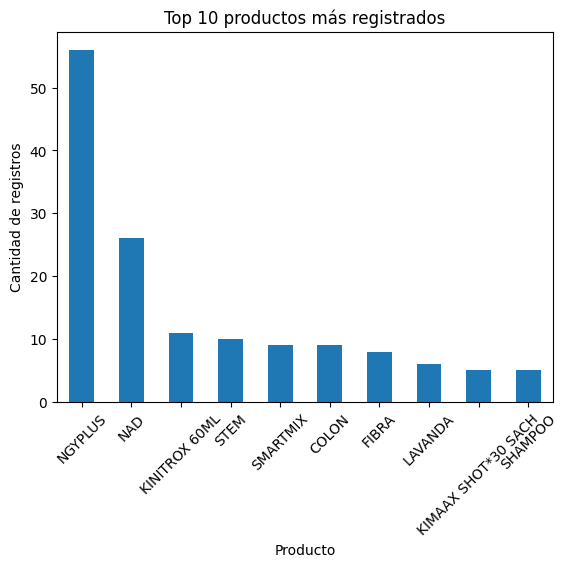

In [26]:
df["Producto"].value_counts().head(10).plot(kind="bar")

plt.title("Top 10 productos más registrados")
plt.xlabel("Producto")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=45)
plt.show()

In [27]:
ventas = df[df["Tipo"] == "VENTA"]

ventas.groupby("Producto")["Cantidad"].sum().sort_values(ascending=False).head(10)

,Cantidad
Producto,
NGYPLUS,885.0
KIMAAX SHOT*60ML,324.0
NAD,46.0
KIMAAX SHOT*30 SACH,35.0
KINITROX 60ML,30.0
SMARTMIX,28.0
STEM,23.0
KI-FEEM,22.0
COLON,16.0


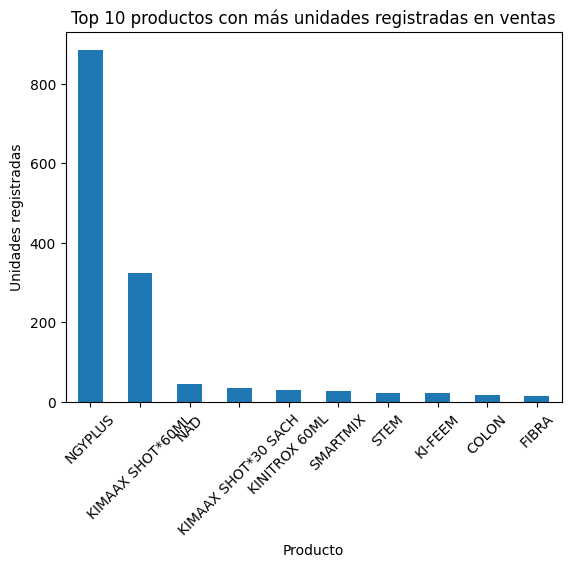

In [28]:
ventas.groupby("Producto")["Cantidad"].sum().sort_values(ascending=False).head(10).plot(kind="bar")

plt.title("Top 10 productos con más unidades registradas en ventas")
plt.xlabel("Producto")
plt.ylabel("Unidades registradas")
plt.xticks(rotation=45)
plt.show()

### Productos con mayor cantidad de unidades registradas

Después de filtrar los movimientos clasificados como `VENTA`, se sumaron las cantidades registradas para cada producto.

El producto `NGYPLUS` presenta la mayor cantidad de unidades registradas, seguido por `KIMAAX SHOT*60ML`.

Los demás productos presentan cantidades considerablemente menores, lo que permite observar una alta concentración del movimiento comercial en algunos productos.

Este análisis incluye registros clasificados como venta independientemente de si su estado de pago es pagado o pendiente.

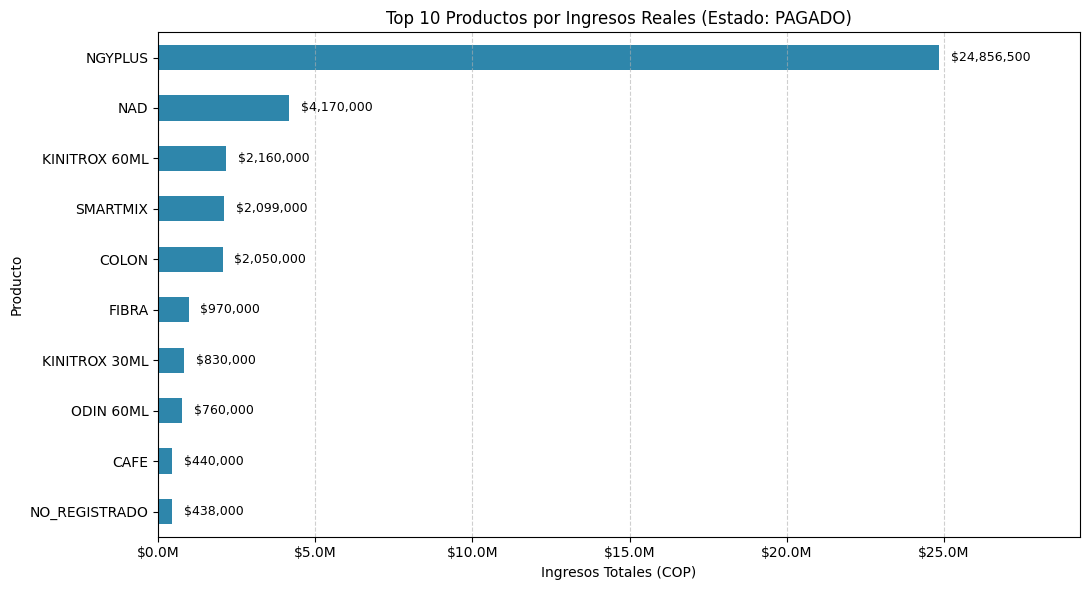

In [29]:
from matplotlib.ticker import FuncFormatter

ventas_pagadas = df[(df["Tipo"] == "VENTA") & (df["Estado_Pago"] == "PAGADO")]

ingresos_producto = (
    ventas_pagadas.groupby("Producto")["Valor_Total_COP"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(11, 6))
ax = ingresos_producto.sort_values().plot(kind="barh", color="#2E86AB")

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"${x/1e6:.1f}M"))

for bar in ax.patches:
    valor = bar.get_width()
    ax.text(
        valor + (ingresos_producto.max() * 0.015),
        bar.get_y() + bar.get_height() / 2,
        f"${valor:,.0f}",
        va="center",
        fontsize=9,
    )

ax.set_xlim(0, ingresos_producto.max() * 1.18)

plt.title("Top 10 Productos por Ingresos Reales (Estado: PAGADO)")
plt.xlabel("Ingresos Totales (COP)")
plt.ylabel("Producto")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Interpretación: Ingresos Reales vs. Volumen de Ventas

Al filtrar exclusivamente por transacciones con estado `PAGADO`, se observa qué productos generan realmente el flujo de caja efectivo para la operación, más allá del simple volumen de unidades despachadas.

* **Alineación comercial:** Los productos que lideran el recaudo efectivo permiten identificar las líneas de mayor rentabilidad real y rotación sana en el negocio.
* **Impacto de cartera pendiente:** Comparar este ranking frente al total de unidades vendidas evidencia el peso de las ventas pendientes de cobro (`PENDIENTE`), resaltando la importancia de cruzar ambas métricas para tomar decisiones sobre inventario, precios y gestión de cartera.

In [30]:
resumen_estado = (
    df.groupby("Estado_Pago", dropna=False)
    .agg(
        Total_Registros=("Estado_Pago", "count"),
        Unidades_Totales=("Cantidad", "sum"),
        Total_COP=("Valor_Total_COP", "sum")
    )
    .sort_values(by="Total_COP", ascending=False)
)

resumen_estado["Total_COP"] = resumen_estado["Total_COP"].map("${:,.0f}".format)
display(resumen_estado)

,Total_Registros,Unidades_Totales,Total_COP
Estado_Pago,,,
PAGADO,95,437.0,"$39,554,500"
PENDIENTE,49,966.0,"$11,994,000"
OBSEQUIO,14,16.0,$0
NO_REGISTRADO,23,262.0,$0


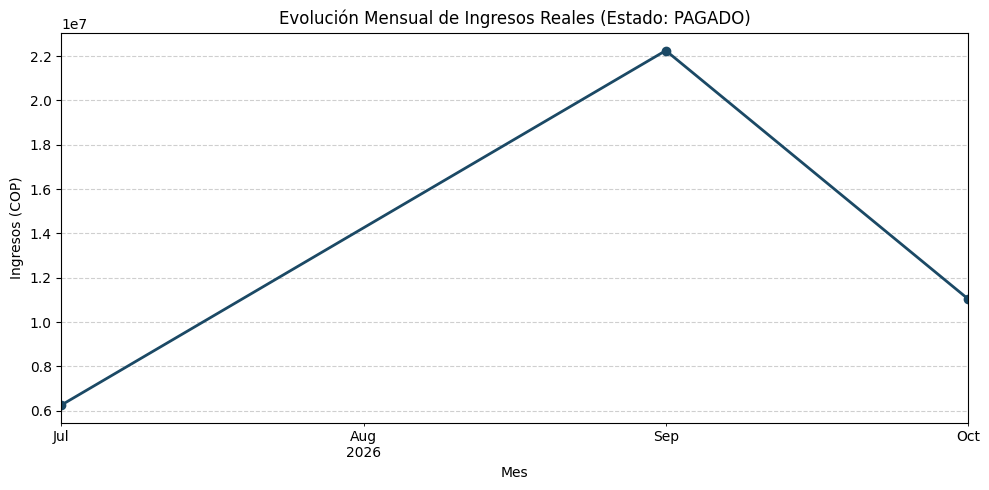

In [31]:
df["Fecha"] = pd.to_datetime(df["Fecha"])
ventas_mes = (
    df[(df["Tipo"] == "VENTA") & (df["Estado_Pago"] == "PAGADO")]
    .groupby(df["Fecha"].dt.to_period("M"))["Valor_Total_COP"]
    .sum()
)

plt.figure(figsize=(10, 5))
ventas_mes.plot(kind="line", marker="o", color="#1B4965", linewidth=2)
plt.title("Evolución Mensual de Ingresos Reales (Estado: PAGADO)")
plt.xlabel("Mes")
plt.ylabel("Ingresos (COP)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

## Conclusiones Generales del Análisis Exploratorio (EDA)

1. **Concentración de productos (Volumen vs. Ingresos):** Mientras que `NGYPLUS` y `KIMAAX SHOT*60ML` lideran en cantidad de unidades registradas, el análisis de ingresos reales (`PAGADO`) permite identificar qué productos aportan mayor flujo de caja efectivo al negocio.
2. **Estado de cartera y recaudo:** Según el resumen financiero por estado de pago, el monto en estado `PAGADO` representa el ingreso real en caja, mientras que los registros en `PENDIENTE` evidencian cartera por cobrar que requiere seguimiento comercial.
3. **Comportamiento temporal:** La serie mensual muestra la tendencia de facturación a lo largo del periodo analizado, identificando los meses de mayor y menor actividad comercial.
4. **Calidad e integridad de los datos:** Se decidió no imputar valores numéricos ni categorías inventadas. Además, se detectó que los 11 registros sin `Tipo` ni `Valor_Total_COP` corresponden íntegramente al pedido **`PED_R0099`** (cliente `CLI_054`), lo que señala un fallo puntual de registro en un pedido específico y no un problema generalizado.

In [32]:
ventas_pagadas = df[
    (df["Tipo"] == "VENTA") &
    (df["Estado_Pago"] == "PAGADO")
]

In [33]:
ventas_pagadas_productos = ventas_pagadas[
    ventas_pagadas["Producto"] != "NO_REGISTRADO"
]

ventas_pagadas_productos.groupby("Producto")["Valor_Total_COP"].sum().sort_values(ascending=False).head(10)

,Valor_Total_COP
Producto,
NGYPLUS,24856500.0
NAD,4170000.0
KINITROX 60ML,2160000.0
SMARTMIX,2099000.0
COLON,2050000.0
FIBRA,970000.0
KINITROX 30ML,830000.0
ODIN 60ML,760000.0
CAFE,440000.0


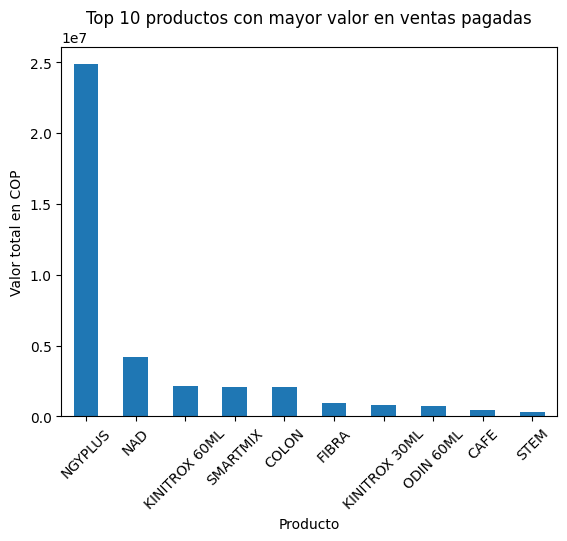

In [34]:
ventas_pagadas_productos.groupby("Producto")["Valor_Total_COP"].sum().sort_values(ascending=False).head(10).plot(kind="bar")

plt.title("Top 10 productos con mayor valor en ventas pagadas")
plt.xlabel("Producto")
plt.ylabel("Valor total en COP")
plt.xticks(rotation=45)
plt.show()

### Interpretación de ventas pagadas por producto

La gráfica muestra los productos con mayor valor acumulado en ventas cuyo estado de pago corresponde a `PAGADO`.

`NGYPLUS` presenta una diferencia considerable frente a los demás productos, siendo el producto que concentra el mayor valor registrado en ventas pagadas.

Después aparecen productos como `NAD`, `KINITROX 60ML`, `SMARTMIX` y `COLON`.

Este resultado permite identificar cuáles productos tienen una mayor participación dentro de los ingresos registrados.

In [35]:
ventas_pagadas["Mes"] = ventas_pagadas["Fecha"].dt.month

ventas_pagadas.groupby("Mes")["Valor_Total_COP"].sum()

/tmp/ipykernel_8117/3246092062.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ventas_pagadas["Mes"] = ventas_pagadas["Fecha"].dt.month


,Valor_Total_COP
Mes,
7,6258000.0
9,22250000.0
10,11046500.0


In [36]:
ventas_mes = ventas_pagadas.groupby("Mes")["Valor_Total_COP"].sum()

ventas_mes = ventas_mes.rename(index={
    7: "Julio",
    9: "Septiembre",
    10: "Octubre"
})

ventas_mes

,Valor_Total_COP
Mes,
Julio,6258000.0
Septiembre,22250000.0
Octubre,11046500.0


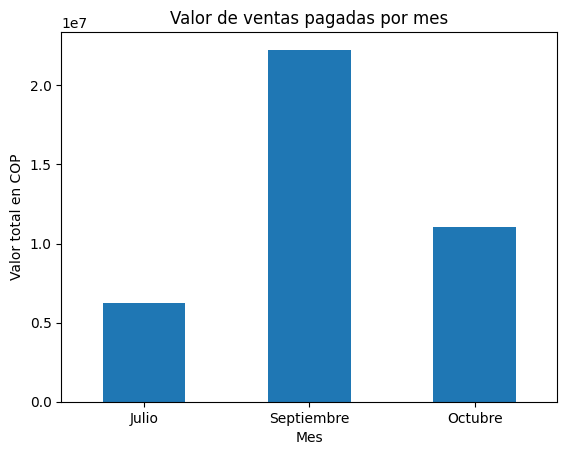

In [37]:
ventas_mes.plot(kind="bar")

plt.title("Valor de ventas pagadas por mes")
plt.xlabel("Mes")
plt.ylabel("Valor total en COP")
plt.xticks(rotation=0)
plt.show()

### Interpretación de ventas pagadas por mes

Se analizaron los valores correspondientes a ventas con estado `PAGADO` y se agruparon por mes.

Septiembre presenta el mayor valor acumulado en ventas pagadas, con aproximadamente $22.250.000 COP.

Octubre ocupa el segundo lugar con aproximadamente $11.046.500 COP y julio presenta aproximadamente $6.258.000 COP.

No se incluyen datos de agosto debido a que el conjunto de datos original no contiene registros correspondientes a ese mes.

In [38]:
ventas_pagadas["Medio_Pago"].value_counts()

,count
Medio_Pago,
NEQUI,44
TRANSFERENCIA,30
EFECTIVO,16
DATAFONO,3
NO_REGISTRADO,1
DAVIPLATA,1


In [39]:
medios_pago = ventas_pagadas[
    ventas_pagadas["Medio_Pago"] != "NO_REGISTRADO"
]["Medio_Pago"].value_counts()

medios_pago

,count
Medio_Pago,
NEQUI,44
TRANSFERENCIA,30
EFECTIVO,16
DATAFONO,3
DAVIPLATA,1


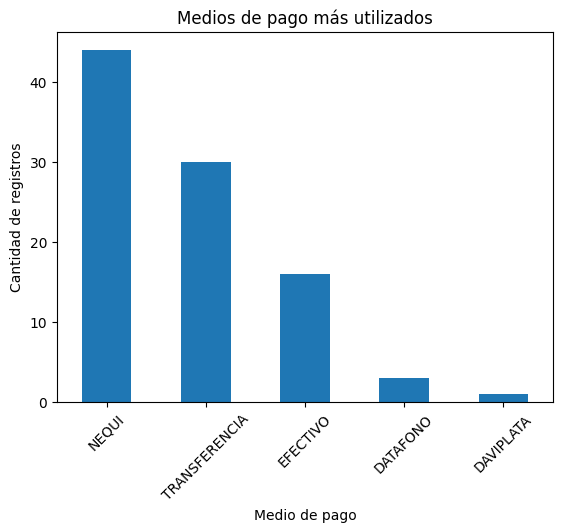

In [40]:
medios_pago.plot(kind="bar")

plt.title("Medios de pago más utilizados")
plt.xlabel("Medio de pago")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=45)
plt.show()

### Interpretación de los medios de pago

Se analizaron los medios de pago utilizados en las ventas cuyo estado corresponde a `PAGADO`.

`NEQUI` es el medio de pago con mayor número de registros, seguido por las transferencias bancarias y el efectivo.

Los pagos mediante datáfono y Daviplata presentan una participación considerablemente menor.

Para este análisis se excluyó la categoría `NO_REGISTRADO`, ya que no corresponde a un medio de pago identificado.

In [41]:
canales = ventas_pagadas[
    ventas_pagadas["Canal_Entrega"] != "NO_ESPECIFICADO"
]["Canal_Entrega"].value_counts()

canales

,count
Canal_Entrega,
ENVIO,37
OFICINA,25
DOMICILIO,13


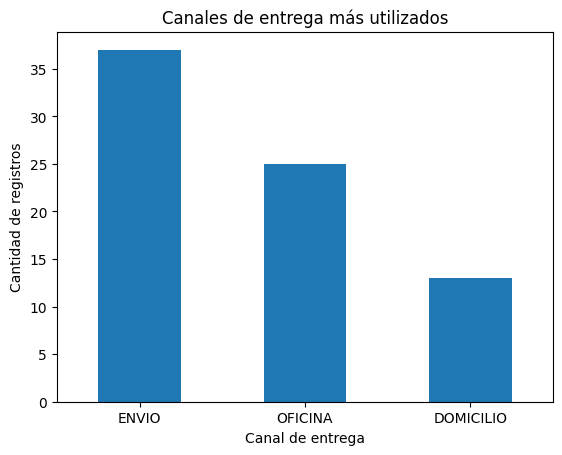

In [42]:
canales.plot(kind="bar")

plt.title("Canales de entrega más utilizados")
plt.xlabel("Canal de entrega")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=0)
plt.show()

### Interpretación de los canales de entrega

Se analizaron los canales de entrega utilizados en las ventas cuyo estado corresponde a `PAGADO`.

El canal `ENVÍO` presenta la mayor cantidad de registros, seguido por las ventas realizadas en `OFICINA` y los servicios de `DOMICILIO`.

Para este análisis se excluyó la categoría `NO_ESPECIFICADO`, ya que no corresponde a un canal de entrega identificado.

In [43]:
print("Registros finales:", df.shape[0])
print("Columnas finales:", df.shape[1])
print("Registros duplicados:", df.duplicated().sum())

print("\nValores faltantes:")
print(df.isnull().sum())

Registros finales: 181
Columnas finales: 13
Registros duplicados: 0

Valores faltantes:
ID_Registro         0
ID_Pedido           0
Fecha               0
Asesor_ID           0
Producto            0
Cantidad            2
Tipo                0
Valor_Total_COP    46
Medio_Pago          0
Estado_Pago         0
Cliente_ID          0
Canal_Entrega       0
Origen_Dato         0
dtype: int64


### Resultado final de la limpieza

Después del proceso de exploración y limpieza, el conjunto de datos conserva 181 registros y 13 variables.

No se encontraron registros duplicados.

Los valores faltantes de las variables `Producto`, `Tipo` y `Cliente_ID` fueron tratados utilizando la categoría `NO_REGISTRADO` cuando no existía información suficiente para completar el dato.

Se conservaron 2 valores faltantes en `Cantidad` y 46 en `Valor_Total_COP`, debido a que no existe información suficiente para determinar estos valores sin alterar los datos originales.

El conjunto de datos queda preparado para continuar con las siguientes etapas del análisis.

In [44]:
df.to_excel("KINNUX_datos_limpios.xlsx", index=False)

print("Archivo limpio guardado correctamente.")

Archivo limpio guardado correctamente.


### Conclusiones del Módulo 1

En esta primera etapa del proyecto se realizó la exploración, revisión y limpieza del conjunto de datos comerciales de KINNUX.

El análisis permitió identificar valores faltantes, registros incompletos y diferencias entre ventas, obsequios y movimientos sin información suficiente.

Se conservaron los registros que podían aportar información útil y se evitó inventar datos cuando no existía evidencia suficiente para completar los valores faltantes.

También se realizaron análisis iniciales sobre productos, unidades registradas, ventas pagadas, medios de pago, canales de entrega y comportamiento mensual.

Entre los principales resultados se encontró que `NGYPLUS` presenta la mayor participación tanto en número de unidades registradas como en valor de ventas pagadas. También se observó que septiembre fue el mes con mayor valor registrado en ventas pagadas dentro del periodo disponible.

Finalmente, se generó una versión limpia del conjunto de datos, que servirá como base para las siguientes etapas del proyecto.

## Módulo 2: Estadística Descriptiva y Análisis Exploratorio

En esta segunda parte calculamos las medidas estadísticas básicas sobre las variables numéricas principales (`Valor_Total_COP` y `Cantidad`) para entender cómo se comportan las ventas de KINNUX.

In [45]:
print("Resumen estadístico general:")
display(df[['Valor_Total_COP', 'Cantidad']].describe().round(2))

for col in ['Valor_Total_COP', 'Cantidad']:
    media = df[col].mean()
    mediana = df[col].median()
    moda = df[col].mode()[0]
    rango = df[col].max() - df[col].min()
    varianza = df[col].var()
    desv_est = df[col].std()

    print(f"\nEstadísticas para {col}:")
    print(f"Media: {round(media, 2)} | Mediana: {round(mediana, 2)} | Moda: {moda}")
    print(f"Rango: {round(rango, 2)} | Varianza: {round(varianza, 2)} | Desviación estándar: {round(desv_est, 2)}")

Resumen estadístico general:


,Valor_Total_COP,Cantidad
count,135.00,179.00
mean,381840.74,9.39
std,688182.29,30.42
min,0.00,1.00
25%,92000.00,1.00
50%,174000.00,2.00
75%,346500.00,4.00
max,4000000.00,300.00



Estadísticas para Valor_Total_COP:
Media: 381840.74 | Mediana: 174000.0 | Moda: 0.0
Rango: 4000000.0 | Varianza: 473594864372.58 | Desviación estándar: 688182.29

Estadísticas para Cantidad:
Media: 9.39 | Mediana: 2.0 | Moda: 1.0
Rango: 299.0 | Varianza: 925.12 | Desviación estándar: 30.42


**Interpretación de las medidas de tendencia central y dispersión:**

| Métrica | Valor_Total_COP | Cantidad (Unidades) |
| :--- | :---: | :---: |
| **Registros válidos** | 135 | 179 |
| **Media (Promedio)** | 381.840,74 COP | 9,39 |
| **Mediana (50%)** | 174.000,00 COP | 2,00 |
| **Moda** | 0,00 COP | 1,00 |
| **Desviación estándar** | 688.182,29 COP | 30,42 |
| **Rango (Min - Max)** | 0 - 4.000.000 COP | 1 - 300 |

* **Tendencia central:** En `Valor_Total_COP`, la media (381.840,74 COP) es más del doble que la mediana (174.000 COP) y la moda es 0 COP debido principalmente a los registros de obsequios y a algunos movimientos pendientes registrados con valor cero. En `Cantidad`, lo más frecuente es pedir 1 unidad (moda) y la mitad de los pedidos son de 2 unidades o menos (mediana), pero el promedio sube a 9,39 porque unas pocas compras muy grandes empujan el valor hacia arriba.
* **Dispersión:** La desviación estándar en ambas variables (688.182,29 COP en valor y 30,42 en cantidad) supera a la propia media, y los rangos son muy amplios (4.000.000 COP y 299 unidades). La varianza del valor total se ve muy alta porque queda expresada en pesos al cuadrado, por lo que la desviación estándar es la referencia principal para confirmar que existe alta variabilidad entre pedidos. Además, `Valor_Total_COP` cuenta con 135 datos numéricos frente a 179 en `Cantidad` por registros pendientes de valorización.

In [46]:
print("Promedio por Tipo de operación:")
display(df.groupby('Tipo')[['Valor_Total_COP', 'Cantidad']].mean().round(2))

print("\nCantidad de operaciones según Tipo y Estado de Pago:")
display(pd.crosstab(df['Tipo'], df['Estado_Pago']))

Promedio por Tipo de operación:


,Valor_Total_COP,Cantidad
Tipo,,
NO_REGISTRADO,NaN,17.45
OBSEQUIO,0.00,1.14
VENTA,426020.66,9.56



Cantidad de operaciones según Tipo y Estado de Pago:


Estado_Pago,NO_REGISTRADO,OBSEQUIO,PAGADO,PENDIENTE
Tipo,,,,
NO_REGISTRADO,11,0,0,0
OBSEQUIO,0,14,0,0
VENTA,12,0,95,49


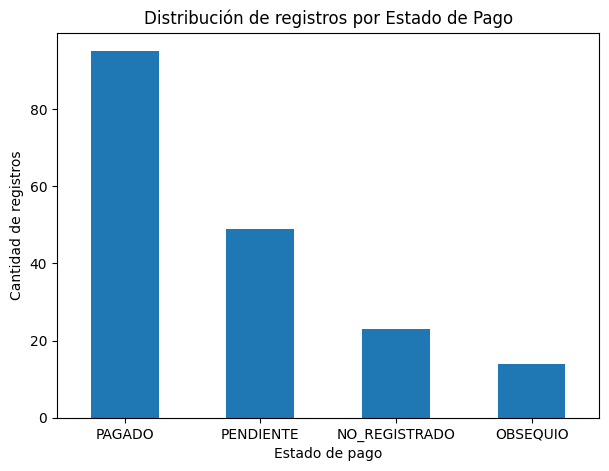

In [47]:
plt.figure(figsize=(7, 5))
df['Estado_Pago'].value_counts().plot(kind='bar', rot=0)
plt.title('Distribución de registros por Estado de Pago')
plt.xlabel('Estado de pago')
plt.ylabel('Cantidad de registros')
plt.show()

Interpretación de la comparación por tipo de operación y estado de pago:

Al comparar los tipos de operación se observan diferencias entre ventas, obsequios y movimientos no registrados. La tabla cruzada permite además identificar cómo se distribuyen estos movimientos según su estado de pago.

Q1: $92,000 COP
Q3: $346,500 COP
IQR: $254,500 COP
Límite superior: $728,250 COP


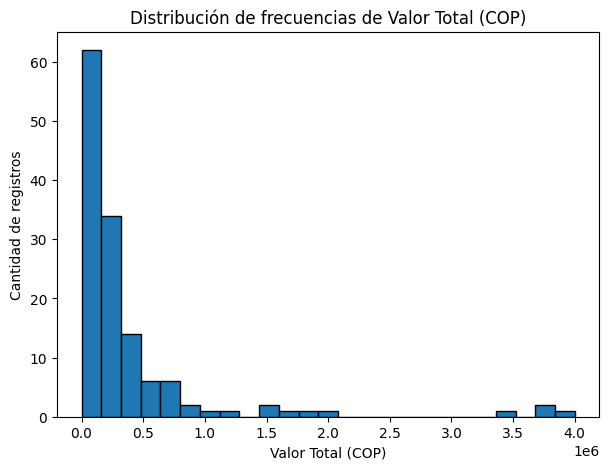

In [48]:
Q1 = df["Valor_Total_COP"].quantile(0.25)
Q3 = df["Valor_Total_COP"].quantile(0.75)

IQR = Q3 - Q1

limite_superior = Q3 + 1.5 * IQR

print(f"Q1: ${Q1:,.0f} COP")
print(f"Q3: ${Q3:,.0f} COP")
print(f"IQR: ${IQR:,.0f} COP")
print(f"Límite superior: ${limite_superior:,.0f} COP")

valor_limpio = df['Valor_Total_COP'].dropna()

plt.figure(figsize=(7, 5))
plt.hist(valor_limpio, bins=25, edgecolor='black')
plt.title('Distribución de frecuencias de Valor Total (COP)')
plt.xlabel('Valor Total (COP)')
plt.ylabel('Cantidad de registros')
plt.show()

**Interpretación de la distribución de Valor Total:**

El histograma muestra un sesgo marcado hacia la derecha. La gran mayoría de las ventas se concentra en montos bajos (por debajo de los 350.000 COP), mientras que la cantidad de transacciones disminuye rápidamente a medida que aumentan los valores facturados.

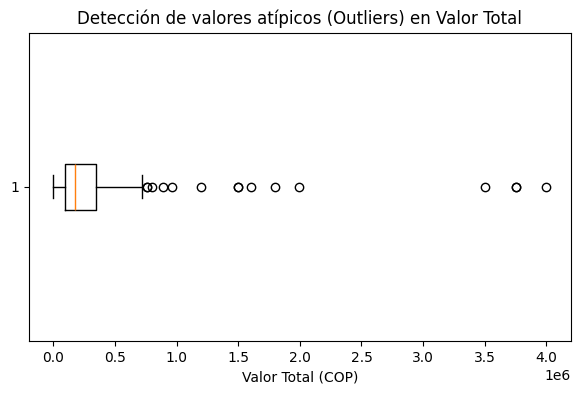

In [49]:
plt.figure(figsize=(7, 4))
plt.boxplot(valor_limpio, vert=False)
plt.title('Detección de valores atípicos (Outliers) en Valor Total')
plt.xlabel('Valor Total (COP)')
plt.show()

**Interpretación de valores atípicos en Valor Total:**

En el diagrama de caja se observan varios puntos aislados a la derecha de los bigotes (ventas superiores a 728.250 COP que llegan hasta los 4.000.000 COP). Estos valores atípicos no corresponden a errores de digitación, sino a pedidos grandes realizados por clientes mayoristas.

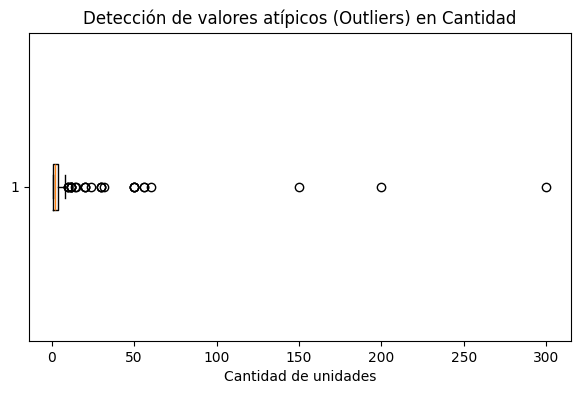

In [50]:
cantidad_limpia = df['Cantidad'].dropna()

plt.figure(figsize=(7, 4))
plt.boxplot(cantidad_limpia, vert=False)
plt.title('Detección de valores atípicos (Outliers) en Cantidad')
plt.xlabel('Cantidad de unidades')
plt.show()

**Interpretación de valores atípicos en Cantidad:**

Al igual que en el valor monetario, el diagrama de caja de cantidades confirma que la mayoría de compras son de pocas unidades (entre 1 y 4), pero existen pedidos atípicos por encima de 8,5 unidades (llegando hasta 300 unidades en una sola operación), lo que refuerza la presencia de compras al por mayor.

**Interpretación de la distribución y valores atípicos (outliers):**

* **Naturaleza de los datos:** El histograma muestra un sesgo marcado hacia la derecha. La gran mayoría de las ventas se concentra por debajo de los 350.000 COP, mientras que la frecuencia cae a medida que aumentan los montos.
* **Valores atípicos (Outliers):** En ambos diagramas de caja se observan puntos aislados a la derecha de los bigotes (ventas superiores a 728.250 COP o pedidos mayores a 8,5 unidades). Estos valores atípicos no corresponden a errores de digitación, sino a compras al por mayor de alto volumen.

Coeficiente de correlación (Cantidad vs Valor_Total_COP): 0.3482


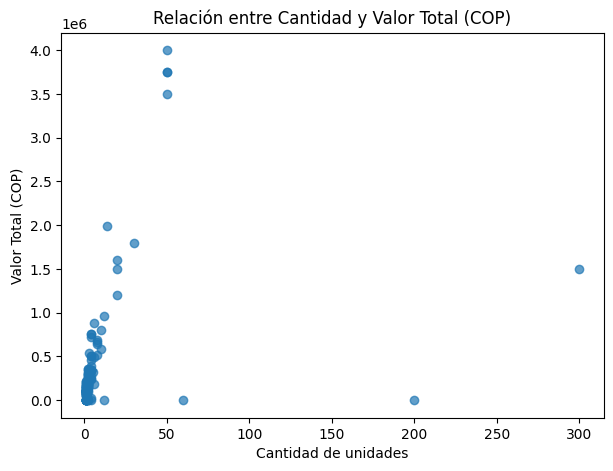

In [51]:
correlacion = df['Cantidad'].corr(df['Valor_Total_COP'])
print(f"Coeficiente de correlación (Cantidad vs Valor_Total_COP): {round(correlacion, 4)}")

plt.figure(figsize=(7, 5))
plt.scatter(df['Cantidad'], df['Valor_Total_COP'], alpha=0.7)
plt.title('Relación entre Cantidad y Valor Total (COP)')
plt.xlabel('Cantidad de unidades')
plt.ylabel('Valor Total (COP)')
plt.show()

**Interpretación de la relación entre variables, hipótesis y contexto profesional:**

* **Relación entre variables:** Relación entre variables: El coeficiente de correlación obtenido es positivo, con un valor aproximado de 0,35. Esto indica una relación positiva débil a moderada entre la cantidad de unidades y el valor total.

  En general, cuando aumenta la cantidad de unidades también tiende a aumentar el valor de la operación, aunque existen otros factores que pueden influir, como el producto y su precio.
* **Hipótesis planteada en equipo:** Los resultados sugieren la posible existencia de diferentes perfiles de compra. La mayoría de los registros corresponde a cantidades pequeñas, mientras que algunas operaciones presentan volúmenes considerablemente mayores.

  Una posible hipótesis es que estos registros de mayor volumen correspondan a clientes mayoristas o distribuidores. Sin embargo, sería necesario contar con una variable que identifique el tipo de cliente para confirmar esta hipótesis.
* **Relevancia en el contexto profesional:** Desde el análisis de datos y la gestión operativa, estos hallazgos evidencian oportunidades concretas de mejora en el registro de información de la empresa: diferenciar desde el inicio el tipo de cliente (detal vs. mayorista), exigir el diligenciamiento completo del valor total y del canal de entrega para evitar registros incompletos, y establecer un control periódico sobre las facturas con estado de pago pendiente.

**Conclusión del Módulo 2:**

A partir del análisis estadístico descriptivo realizado en equipo sobre los datos de KINNUX, resumimos los principales hallazgos de esta etapa:

* **Comportamiento de las ventas:** La mayoría de las transacciones corresponden a compras pequeñas (mediana de 2 unidades y 174.000 COP), pero existen pedidos mayoristas de hasta 300 unidades y 4.000.000 COP que elevan el promedio y la desviación estándar.
* **Consistencia de los datos:** Se comprobó que los obsequios quedaron correctamente registrados en 0 COP, mientras que las ventas concentran los ingresos reales. No obstante, se identificaron 46 registros sin valor monetario asignado y operaciones con estado de pago pendiente que requieren seguimiento.
* **Relación y segmentación:** La correlación positiva entre unidades y valor total, junto con el análisis de valores atípicos, confirma la presencia de dos perfiles claros de clientes (detal y mayorista) dentro de la operación.

## Módulo 3: Modelado Matemático y Storytelling

### Objetivo

En esta etapa se busca comunicar los principales hallazgos obtenidos durante el análisis de los datos de KINNUX mediante visualizaciones claras, una narrativa basada en datos y la aplicación de un modelo predictivo sencillo.

Para el componente predictivo se utilizará una regresión lineal simple con el propósito de analizar si la cantidad de unidades registradas puede utilizarse para estimar el valor total de una operación comercial.

Finalmente, se interpretarán los resultados obtenidos y se planteará una posible aplicación profesional del análisis realizado.

In [52]:
datos_modelo = df[
    (df["Tipo"] == "VENTA") &
    (df["Cantidad"].notnull()) &
    (df["Valor_Total_COP"].notnull()) &
    (df["Valor_Total_COP"] > 0)
]

datos_modelo[["Cantidad", "Valor_Total_COP"]].head().style.format({
    "Cantidad": "{:.0f}",
    "Valor_Total_COP": "${:,.0f} COP"
})

,Cantidad,Valor_Total_COP
0,1,"$115,000 COP"
1,1,"$110,000 COP"
2,1,"$165,000 COP"
4,50,"$3,500,000 COP"
7,300,"$1,500,000 COP"


In [53]:
datos_modelo.shape

(112, 13)

In [54]:
X = datos_modelo[["Cantidad"]]
y = datos_modelo["Valor_Total_COP"]

In [55]:
print("Variable utilizada para predecir: Cantidad")
print("Variable que queremos predecir: Valor_Total_COP")

Variable utilizada para predecir: Cantidad
Variable que queremos predecir: Valor_Total_COP


In [56]:
from sklearn.model_selection import train_test_split

X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [57]:
print("Datos para entrenamiento:", len(X_entrenamiento))
print("Datos para prueba:", len(X_prueba))

Datos para entrenamiento: 89
Datos para prueba: 23


In [58]:
from sklearn.linear_model import LinearRegression

modelo = LinearRegression()

modelo.fit(X_entrenamiento, y_entrenamiento)

print("Modelo entrenado correctamente.")

Modelo entrenado correctamente.


In [59]:
predicciones = modelo.predict(X_prueba)

print("Predicciones realizadas correctamente.")

Predicciones realizadas correctamente.


In [60]:
from sklearn.metrics import mean_absolute_error, r2_score

mae = mean_absolute_error(y_prueba, predicciones)
r2 = r2_score(y_prueba, predicciones)

print(f"Error promedio del modelo: ${mae:,.0f} COP")
print(f"R² del modelo: {r2:.2f}")

Error promedio del modelo: $937,865 COP
R² del modelo: -29.02


### Evaluación inicial del modelo

El primer modelo utilizó la cantidad de unidades para intentar predecir el valor total de las ventas, incluyendo diferentes productos.

El error promedio obtenido fue de aproximadamente **$937,865 COP** y el valor de R² fue **-29.02**, lo que indica que este modelo no realiza predicciones adecuadas.

Esto puede explicarse porque los productos de KINNUX tienen precios diferentes. Por esta razón, la cantidad de unidades por sí sola no es suficiente para estimar el valor de una operación cuando se mezclan diferentes productos.

A partir de este resultado se decidió realizar un modelo más específico utilizando un solo producto con suficiente cantidad de registros.

In [61]:
# Seleccionar únicamente las ventas de NGYPLUS

datos_ngyplus = datos_modelo[
    datos_modelo["Producto"] == "NGYPLUS"
]

print("Registros disponibles de NGYPLUS:", len(datos_ngyplus))

Registros disponibles de NGYPLUS: 48


In [62]:
X_ngyplus = datos_ngyplus[["Cantidad"]]
y_ngyplus = datos_ngyplus["Valor_Total_COP"]

X_ent_ngy, X_prueba_ngy, y_ent_ngy, y_prueba_ngy = train_test_split(
    X_ngyplus,
    y_ngyplus,
    test_size=0.20,
    random_state=42
)

print("Datos para entrenamiento:", len(X_ent_ngy))
print("Datos para prueba:", len(X_prueba_ngy))

Datos para entrenamiento: 38
Datos para prueba: 10


In [63]:
modelo_ngy = LinearRegression()

modelo_ngy.fit(X_ent_ngy, y_ent_ngy)

print("Modelo de NGYPLUS entrenado correctamente.")

Modelo de NGYPLUS entrenado correctamente.


In [64]:
predicciones_ngy = modelo_ngy.predict(X_prueba_ngy)

print("Predicciones de NGYPLUS realizadas correctamente.")

Predicciones de NGYPLUS realizadas correctamente.


In [65]:
mae_ngy = mean_absolute_error(y_prueba_ngy, predicciones_ngy)
r2_ngy = r2_score(y_prueba_ngy, predicciones_ngy)

print(f"Error promedio del modelo: ${mae_ngy:,.0f} COP")
print(f"R² del modelo: {r2_ngy:.2f}")

Error promedio del modelo: $80,903 COP
R² del modelo: 0.98


### Evaluación del modelo de NGYPLUS

Después de identificar las limitaciones del modelo inicial, se realizó una segunda regresión lineal utilizando únicamente las ventas de `NGYPLUS`.

El nuevo modelo obtuvo un error promedio de aproximadamente **$80,903 COP** y un valor de **R² de 0.98**.

Este resultado representa una mejora considerable frente al modelo inicial y muestra que, para un mismo producto, la cantidad de unidades tiene una relación mucho más clara con el valor total de la operación.

El valor de R² indica que el modelo explica aproximadamente el 98 % de la variación observada en el valor de las ventas de NGYPLUS.

Sin embargo, este modelo debe interpretarse específicamente para este producto y no utilizarse directamente para estimar el valor de otros productos de KINNUX.

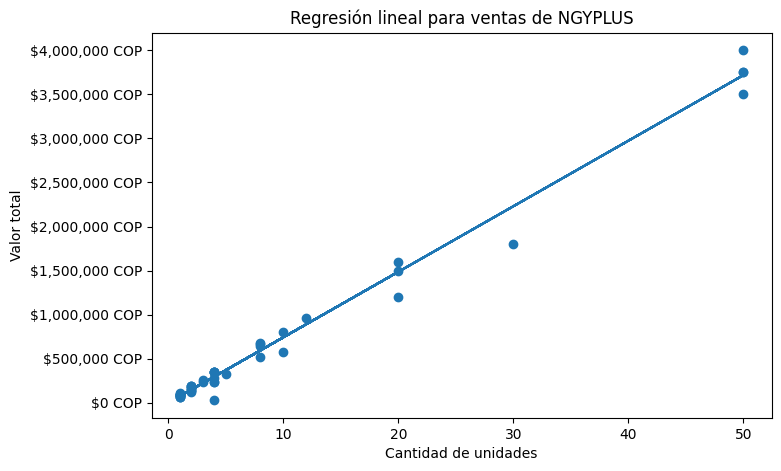

In [66]:
from matplotlib.ticker import FuncFormatter

plt.figure(figsize=(8, 5))

plt.scatter(
    datos_ngyplus["Cantidad"],
    datos_ngyplus["Valor_Total_COP"]
)

plt.plot(
    X_ngyplus,
    modelo_ngy.predict(X_ngyplus)
)

plt.title("Regresión lineal para ventas de NGYPLUS")
plt.xlabel("Cantidad de unidades")
plt.ylabel("Valor total")

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x:,.0f} COP")
)

plt.show()

### Interpretación visual del modelo

Los puntos representan las ventas reales registradas de `NGYPLUS`, mientras que la línea representa el comportamiento estimado por el modelo de regresión lineal.

Se observa que la mayoría de los registros se encuentran cerca de la línea de tendencia, lo que indica una relación fuerte entre la cantidad de unidades de NGYPLUS y el valor total de la operación.

Este comportamiento coincide con el resultado obtenido en la evaluación del modelo, donde se obtuvo un R² de 0.98.

In [67]:
cantidad_ejemplo = pd.DataFrame({
    "Cantidad": [10]
})

valor_estimado = modelo_ngy.predict(cantidad_ejemplo)[0]

print("Cantidad de NGYPLUS: 10 unidades")
print(f"Valor estimado: ${valor_estimado:,.0f} COP")

Cantidad de NGYPLUS: 10 unidades
Valor estimado: $743,657 COP


### Ejemplo de predicción

Como ejemplo práctico, se utilizó el modelo para estimar el valor de una operación correspondiente a 10 unidades de `NGYPLUS`.

El modelo estimó un valor aproximado de **$743,657 COP**.

Esta predicción muestra cómo un modelo sencillo puede utilizar datos históricos para estimar el valor esperado de una nueva operación.

Sin embargo, el resultado debe considerarse una estimación y no un valor exacto, ya que las condiciones comerciales pueden variar entre operaciones.

### Storytelling: de los datos a las decisiones

El análisis comenzó con un conjunto de registros comerciales de KINNUX que presentaba información incompleta, diferentes tipos de operaciones y valores faltantes.

Después del proceso de limpieza fue posible identificar patrones importantes en el comportamiento comercial de la empresa.

Uno de los principales hallazgos fue que `NGYPLUS` concentra una parte importante tanto de las unidades registradas como del valor de las ventas pagadas. También se observó que septiembre presentó el mayor valor acumulado en ventas pagadas dentro del periodo analizado.

El análisis estadístico mostró además que existen operaciones de bajo volumen y otras considerablemente mayores, lo que sugiere diferentes comportamientos de compra.

Finalmente, se probó un modelo de regresión lineal. El primer modelo intentó predecir el valor de cualquier venta utilizando únicamente la cantidad y presentó resultados poco adecuados. Al analizar un solo producto, `NGYPLUS`, el modelo mejoró considerablemente y alcanzó un R² de 0.98.

Esto demuestra que el contexto de los datos es fundamental: no siempre un modelo general produce buenos resultados y, en algunos casos, segmentar correctamente la información permite obtener estimaciones más útiles.

### **Aplicación profesional del análisis**

Los resultados obtenidos pueden utilizarse en KINNUX como apoyo para la toma de decisiones comerciales y para mejorar la gestión de la información de ventas.

El análisis permite identificar productos con mayor movimiento, periodos con mayor valor en ventas pagadas, medios de pago utilizados y diferentes comportamientos de compra.

El modelo predictivo desarrollado para `NGYPLUS` también demuestra cómo los datos históricos pueden utilizarse para realizar estimaciones sobre nuevas operaciones. Por ejemplo, conociendo la cantidad de unidades solicitadas, el modelo puede generar un valor aproximado de la operación.

En un entorno profesional, este tipo de análisis podría integrarse posteriormente en herramientas de seguimiento comercial o dashboards que permitan monitorear ventas, identificar tendencias y apoyar la planificación de inventario y estrategias comerciales.

Además, el proyecto demuestra la importancia de mantener registros completos y organizados, ya que la calidad de los datos influye directamente en la calidad de los análisis y de las predicciones.

### **Conclusiones del Módulo 3**

En esta etapa se utilizaron visualizaciones y técnicas de modelado para transformar los resultados del análisis en información comprensible y útil.

Inicialmente se construyó un modelo de regresión lineal utilizando la cantidad de unidades para predecir el valor total de diferentes productos. Este modelo presentó un error promedio de **$937,865 COP** y un R² de **-29.02**, demostrando que la cantidad por sí sola no permite estimar adecuadamente el valor cuando se mezclan productos con precios diferentes.

Posteriormente se desarrolló un segundo modelo utilizando únicamente las ventas de `NGYPLUS`. Este modelo obtuvo un error promedio de **$80,903 COP** y un R² de **0.98**, mostrando una relación mucho más clara entre la cantidad de unidades y el valor total para este producto.

Como ejemplo, el modelo estimó que una operación de 10 unidades de NGYPLUS tendría un valor aproximado de **$743,657 COP**.

Estos resultados muestran que la selección adecuada de los datos y el contexto de cada variable son fundamentales para construir modelos predictivos útiles.

## Conclusiones y Recomendaciones

### 1. Calidad y Gestión de Datos
* **Integridad de registros:** El conjunto de datos original (181 registros y 13 variables) no presenta filas duplicadas, pero sí evidenció falencias en la captura de información operativa, concentradas principalmente en la ausencia de valores monetarios (`Valor_Total_COP` con 50 nulos iniciales) y registros sin tipificar (`Tipo` y `Estado_Pago` como `NO_REGISTRADO`).
* **Criterio de limpieza:** La imputación controlada mediante la categoría `NO_REGISTRADO` y la asignación de $0 únicamente a los obsequios permitió conservar el 100 % de los registros sin sesgar los indicadores financieros ni inventar datos inexistentes.
* **Recomendación técnica:** Se sugiere implementar validaciones obligatorias en el sistema de registro de pedidos de KINNUX S.A.S. (especialmente en los campos de valor total, producto y canal de entrega) para evitar la pérdida de trazabilidad financiera en futuros análisis.

### 2. Comportamiento Comercial y Productos
* **Concentración de la demanda:** Existe una alta concentración comercial en productos estrella. **NGYPLUS** lidera tanto en frecuencia de aparición (56 registros) como en volumen total vendido (885 unidades), seguido a distancia por **KIMAAX SHOT*60ML** (324 unidades) y **NAD** (46 unidades).
* **Diferencia entre frecuencia y volumen:** Productos como `KIMAAX SHOT*60ML` tienen pocos registros de pedido, pero mueven grandes cantidades por transacción, lo que sugiere compras al por mayor o distribución a clientes recurrentes.
* **Cartera y recaudo:** De los 181 movimientos analizados, 95 corresponden a ventas efectivamente pagadas, mientras que 49 se encuentran en estado `PENDIENTE`. Hacer seguimiento a estos registros pendientes es prioritario para asegurar el flujo de caja de la empresa.

### 3. Trabajo Futuro (Próximas Etapas)
* Incorporar la base de datos ampliada (registros sintéticos) para evaluar el comportamiento estadístico a mayor escala.
* Cruzar el volumen de unidades con el ingreso neto (`Valor_Total_COP`) filtrado por ventas pagadas, analizar la estacionalidad mensual de las ventas y evaluar el rendimiento individual por asesor comercial (`Asesor_ID`)[cite: 7].